# 06 — Support Vector Machine



## 1. Dữ liệu và preprocessing thống nhất
Cùng cách chia 80/20, `random_state=42`, `stratify=y`. Preprocessing được fit trong mỗi fold CV.

In [5]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import RANDOM_STATE, SCORING, make_cv
from src.data import load_train_test
from src.modeling import (
    build_preprocessor,
    make_pipeline,
    evaluate_cv,
    scan_oof_thresholds,
    save_cv_report,
)

X_train, X_test, y_train, y_test, NUM_COLS, CAT_COLS = load_train_test()
preprocessor = build_preprocessor(NUM_COLS, CAT_COLS, min_frequency=50)
cv = make_cv()

MODEL_NAME = "Support Vector Machine (LinearSVC)"
REPORT_FILE = "06_svm.json"
BASE_MODEL = LinearSVC(dual="auto", max_iter=5000, random_state=RANDOM_STATE)
PARAM_GRID = {
    "model__C": [0.001, 0.01, 0.1, 1.0, 10.0],
    "model__class_weight": [None, "balanced"],
}

print(f"Ready | {MODEL_NAME} | Train={X_train.shape} | Test={X_test.shape} | Churn={y_train.mean():.4f}")

Ready | Support Vector Machine (LinearSVC) | Train=(40837, 53) | Test=(10210, 53) | Churn=0.2882


## 2. E1 — Baseline 5-fold CV
Đánh giá F1, Recall, Precision, ROC-AUC và PR-AUC; phân tích độ lệch chuẩn giữa các fold.

In [6]:
t0 = time.time()
baseline_pipe = make_pipeline(preprocessor, BASE_MODEL)
base_cv, base_summary = evaluate_cv(baseline_pipe, X_train, y_train, cv)
print(f"E1 xong sau {time.time() - t0:.1f}s")
display(base_summary)

E1 xong sau 20.9s


,metric,mean,std
0,f1,0.0541,0.0043
1,recall,0.0285,0.0024
2,precision,0.5132,0.0234
3,roc_auc,0.6134,0.0060
4,ap,0.3767,0.0054


## 3. E2 — Hyperparameter tuning
RandomizedSearchCV tối ưu F1 trong Train; so sánh baseline và tuned theo cùng cross-validation. Không chọn dựa trên Test.

In [7]:
t0 = time.time()
search = GridSearchCV(
    estimator=clone(baseline_pipe),
    param_grid=PARAM_GRID,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)
search.fit(X_train, y_train)

best_model = clone(search.best_estimator_.named_steps["model"])
tuned_cv, tuned_summary = evaluate_cv(make_pipeline(preprocessor, best_model), X_train, y_train, cv)

print(f"Tuning LinearSVC xong sau {time.time() - t0:.1f}s | Best CV F1: {search.best_score_:.4f}")
print("Best params:", search.best_params_)
display(
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")[["params", "mean_train_score", "mean_test_score", "std_test_score"]]
    .round(4)
)
display(tuned_summary)

# Đối chiếu thêm nhánh phi tuyến RBF (xấp xỉ Nystroem để chạy nhanh trên 40.837 dòng)
t1 = time.time()
rbf_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("rbf_map", Nystroem(kernel="rbf", n_components=300, random_state=RANDOM_STATE)),
    ("model", LinearSVC(
        dual="auto",
        C=search.best_params_["model__C"],
        class_weight="balanced",
        max_iter=5000,
        random_state=RANDOM_STATE,
    )),
])
rbf_cv, rbf_summary = evaluate_cv(rbf_pipe, X_train, y_train, cv)
print(f"\nRBF Approximation xong sau {time.time() - t1:.1f}s")
display(
    pd.DataFrame({
        "metric": list(SCORING),
        "best_linear_svm": [tuned_cv[f"test_{k}"].mean() for k in SCORING],
        "rbf_approx_svm": [rbf_cv[f"test_{k}"].mean() for k in SCORING],
    }).round(4)
)

Tuning LinearSVC xong sau 93.4s | Best CV F1: 0.4477
Best params: {'model__C': 0.001, 'model__class_weight': 'balanced'}


,params,mean_train_score,mean_test_score,std_test_score
1,"{'model__C': 0.001, 'model__class_weight': 'ba...",0.4560,0.4477,0.0054
3,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.4592,0.4473,0.0049
5,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.4592,0.4444,0.0053
7,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.4593,0.4442,0.0054
9,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.4593,0.4441,0.0053
6,"{'model__C': 1.0, 'model__class_weight': None}",0.0594,0.0541,0.0043
8,"{'model__C': 10.0, 'model__class_weight': None}",0.0595,0.0541,0.0043
4,"{'model__C': 0.1, 'model__class_weight': None}",0.0577,0.0530,0.0043
2,"{'model__C': 0.01, 'model__class_weight': None}",0.0501,0.0452,0.0033
0,"{'model__C': 0.001, 'model__class_weight': None}",0.0266,0.0259,0.0049


,metric,mean,std
0,f1,0.4477,0.0054
1,recall,0.5829,0.0081
2,precision,0.3635,0.0050
3,roc_auc,0.6194,0.0070
4,ap,0.3794,0.0055



RBF Approximation xong sau 10.3s


,metric,best_linear_svm,rbf_approx_svm
0,f1,0.4477,0.4282
1,recall,0.5829,0.5571
2,precision,0.3635,0.3477
3,roc_auc,0.6194,0.5929
4,ap,0.3794,0.3573


## 4. E3 — Mất cân bằng lớp
So sánh baseline với `class_weight="balanced"` (nếu thuật toán hỗ trợ). SMOTE là thí nghiệm mở rộng: chỉ được dùng trong pipeline của từng fold Train, không áp dụng lên Test.

In [8]:
t0 = time.time()
weighted_pipe = make_pipeline(
    preprocessor,
    clone(BASE_MODEL).set_params(class_weight="balanced"),
)
weighted_cv, _ = evaluate_cv(weighted_pipe, X_train, y_train, cv)

smote_pipe = ImbPipeline([
    ("preprocessor", clone(preprocessor)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", clone(BASE_MODEL)),
])
smote_cv, _ = evaluate_cv(smote_pipe, X_train, y_train, cv)

display(
    pd.DataFrame({
        "metric": list(SCORING),
        "baseline": [base_cv[f"test_{k}"].mean() for k in SCORING],
        "class_weight_balanced": [weighted_cv[f"test_{k}"].mean() for k in SCORING],
        "smote": [smote_cv[f"test_{k}"].mean() for k in SCORING],
    }).round(4)
)
print(f"E3 xong sau {time.time() - t0:.1f}s")

,metric,baseline,class_weight_balanced,smote
0,f1,0.0541,0.4442,0.4404
1,recall,0.0285,0.5759,0.5816
2,precision,0.5132,0.3615,0.3544
3,roc_auc,0.6134,0.6135,0.6071
4,ap,0.3767,0.3762,0.3703


E3 xong sau 61.7s


## 5. E4 — Feature selection (thử nghiệm bổ sung)
Dùng `SelectPercentile` trong pipeline CV để tránh leakage. Cần giải thích ảnh hưởng đến F1 và thời gian chạy.

In [9]:
t0 = time.time()
fs_pipe = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selector", SelectPercentile(score_func=f_classif, percentile=60)),
    ("model", clone(best_model)),
])
fs_cv, _ = evaluate_cv(fs_pipe, X_train, y_train, cv)

display(
    pd.DataFrame({
        "metric": list(SCORING),
        "tuned_full": [tuned_cv[f"test_{k}"].mean() for k in SCORING],
        "tuned_top60pct": [fs_cv[f"test_{k}"].mean() for k in SCORING],
    }).round(4)
)
print(f"E4 xong sau {time.time() - t0:.1f}s")

,metric,tuned_full,tuned_top60pct
0,f1,0.4477,0.4473
1,recall,0.5829,0.5827
2,precision,0.3635,0.3630
3,roc_auc,0.6194,0.6189
4,ap,0.3794,0.3786


E4 xong sau 7.2s


## 6. E5 — Stability analysis
So sánh F1 trung bình và độ lệch chuẩn giữa các fold, sau đó có thể mở rộng bằng RepeatedStratifiedKFold.

,fold,baseline_f1,tuned_f1,tuned_roc_auc
0,1,0.0494,0.4530,0.6304
1,2,0.0500,0.4524,0.6180
2,3,0.0600,0.4510,0.6238
3,4,0.0526,0.4417,0.6139
4,5,0.0583,0.4407,0.6108


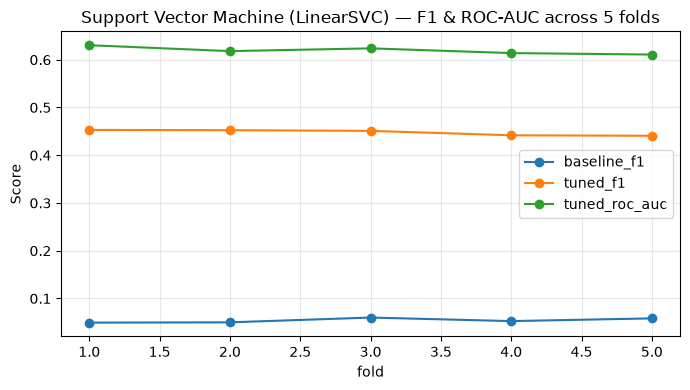

In [10]:
stability = pd.DataFrame({
    "fold": range(1, 6),
    "baseline_f1": base_cv["test_f1"],
    "tuned_f1": tuned_cv["test_f1"],
    "tuned_roc_auc": tuned_cv["test_roc_auc"],
}).round(4)
display(stability)

ax = stability.set_index("fold").plot(
    marker="o", figsize=(7, 4), title=f"{MODEL_NAME} — F1 & ROC-AUC across 5 folds"
)
ax.set_ylabel("Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. E6 — Threshold analysis trên validation
Dùng out-of-fold probabilities để khảo sát threshold; **không dùng Test**. Để tiết kiệm thời gian, mặc định khảo sát baseline.

In [11]:
t0 = time.time()
thresh_df, best_threshold, best_oof_f1 = scan_oof_thresholds(
    preprocessor, best_model, X_train, y_train, cv
)
print(f"E6 xong sau {time.time() - t0:.1f}s | Best OOF threshold: {best_threshold} (F1={best_oof_f1:.4f})")
display(thresh_df)

report = {
    "model": MODEL_NAME,
    "baseline_cv": {k: round(float(base_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "weighted_cv": {k: round(float(weighted_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "smote_cv": {k: round(float(smote_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "tuned_cv": {k: round(float(tuned_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "rbf_approx_cv": {k: round(float(rbf_cv[f"test_{k}"].mean()), 4) for k in SCORING},
    "tuned_cv_f1_std": round(float(tuned_cv["test_f1"].std()), 4),
    "tuned_best_cv_f1": round(float(search.best_score_), 4),
    "tuned_best_params": {
        k.replace("model__", ""): (float(v) if isinstance(v, np.floating) else v)
        for k, v in search.best_params_.items()
    },
    "best_oof_threshold": best_threshold,
    "best_oof_f1_at_threshold": round(best_oof_f1, 4),
}

saved_path = save_cv_report(REPORT_FILE, report)
print("Đã lưu kết quả CV tại:", saved_path)

E6 xong sau 8.8s | Best OOF threshold: 0.25 (F1=0.4710)


,threshold,precision,recall,f1
0,0.15,0.2914,0.9907,0.4503
1,0.20,0.3058,0.9455,0.4622
2,0.25,0.3365,0.7848,0.4710
3,0.30,0.3763,0.5082,0.4324
4,0.35,0.4101,0.2614,0.3193
5,0.40,0.4355,0.1089,0.1743
6,0.45,0.4699,0.0417,0.0766
7,0.50,0.4575,0.0133,0.0258
8,0.55,0.4236,0.0052,0.0102
9,0.60,0.4366,0.0026,0.0052


Đã lưu kết quả CV tại: E:\07_Active_Projects\coding\mechine_learning\customer_churn_ml\telecom-churn-ml\results\metrics\06_svm.json
